# Khmer TTS Step 2: Audio preprocessing 
**Input:** `speaker_manifest.csv` from Step 1 + the raw `.wav` files.
**Output:** a folder of clean, standardized wavs + `metadata_train/val/test.csv` that the VITS trainer (Step 3) reads directly.

| # | What | Why it matters for TTS |
|---|---|---|
| 1 | Find the real wav for every sentence | stub files like `._name.wav` are not audio |
| 2 | Inspect format (sample rate, channels, bit depth) | decides the target format |
| 3 | Quality checks: corrupt, clipping, noise, silence, length | bad audio teaches the model bad speech |
| 4 | Detect transcript–audio mismatches | a wrong transcript is the #1 cause of garbled TTS |
| 5 | Standardize: mono, one sample rate, trim silence, normalize loudness | VITS needs identical format for every clip |
| 6 | Split train / val / test | you need unseen sentences to evaluate fairly |
| 7 | Export in the format the trainer expects | |

Original files are **never modified**; processed copies go to a new folder.

In [4]:
# Check the environment (run first)
import sys, importlib
print("Python:", sys.version.split()[0])
for m, pkg in [("pandas","pandas"),("numpy","numpy"),("matplotlib","matplotlib"),("soundfile","soundfile"),
               ("librosa","librosa"),("pyloudnorm","pyloudnorm (pip install pyloudnorm)"),("tqdm","tqdm")]:
    try: print(f"OK      {m} {getattr(importlib.import_module(m), '__version__', '')}")
    except Exception: print(f"MISSING {m}  ->  install: {pkg}")

Python: 3.12.15
OK      pandas 3.0.6
OK      numpy 2.5.4
OK      matplotlib 3.11.2
OK      soundfile 0.14.0
OK      librosa 1.0.0
OK      pyloudnorm 
OK      tqdm 4.70.1


## 0. Configuration


In [5]:
from pathlib import Path
import re, json, random
import numpy as np, pandas as pd
import soundfile as sf, librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from IPython.display import Audio, display

# ---- paths (change these) ----
MANIFEST_PATH = Path("outputs/speaker_manifest.csv")      # from Step 1
WAV_DIR       = Path(r"C:\Users\MSI\Pictures\NLPproject\dataset\data")   # folder with recipes/, wedding/, ...
PROC_DIR      = Path("processed")                          # everything we create goes here

# ---- audio standard ----
TARGET_SR   = 22050
TRIM_DB     = 35        # silence = more than 35 dB below the clip's loudest part
KEEP_PAD    = 0.10      # seconds of silence kept at each end (don't cut breaths/onsets)
TARGET_LUFS = -23.0     # loudness target (same loudness for every clip)

# ---- quality thresholds ----
MIN_DUR, MAX_DUR = 1.0, 15.0     # seconds (before trimming)
MAX_CLIP_RATIO   = 0.001         # > 0.1% of samples at full scale = clipped
MIN_PEAK         = 0.05          # almost silent file
SNR_PCT          = 1             # flag the worst 1% by noise estimate
MISMATCH_Z       = 4.0           # robust z-score of chars-per-second

# ---- split ----
VAL_FRAC, TEST_FRAC, SEED = 0.02, 0.02, 42
N_WORKERS = 8

(PROC_DIR/"wavs").mkdir(parents=True, exist_ok=True)
(PROC_DIR/"reports").mkdir(exist_ok=True)

## 1. Load the manifest and find the real wav files
Your manifest stores a `wav_path` column, but it may point at macOS stub files (`._name.wav`, a few KB, not audio). So we **ignore that column** and rebuild the link ourselves:

`{Speaker ID}_khm_{Sentence ID}.wav`  →  real file on disk

In [6]:
man = pd.read_csv(MANIFEST_PATH)
print(man.shape, "| speakers:", man["Speaker ID"].unique())

# index every REAL wav (skip macOS junk)
index = {}
for p in WAV_DIR.rglob("*.wav"):
    if p.name.startswith("._") or "__MACOSX" in p.parts:
        continue
    index[p.name] = p
print("real wav files found:", len(index))

man["file_name"] = man["Speaker ID"] + "_khm_" + man["Sentence ID"] + ".wav"
man["src_path"]  = man["file_name"].map(index)
missing = man[man["src_path"].isna()]
print("sentences with NO wav file:", len(missing))
man = man[man["src_path"].notna()].reset_index(drop=True)
print("usable pairs so far:", len(man))
missing[["Sentence ID","Topic"]].head()

(10621, 8) | speakers: <StringArray>
['f-adt2-0002']
Length: 1, dtype: str
real wav files found: 45627
sentences with NO wav file: 0
usable pairs so far: 10621


,Sentence ID,Topic


## 2. Inspect the raw audio format
We read only the **header** of each file (very fast). We want to know: sample rates, mono/stereo, bit depth.

In [7]:
def header(p):
    try:
        i = sf.info(p)
        return dict(sr=i.samplerate, channels=i.channels, subtype=i.subtype, dur=i.duration, hdr_ok=True)
    except Exception as e:
        return dict(sr=None, channels=None, subtype=None, dur=None, hdr_ok=False)

with ThreadPoolExecutor(N_WORKERS) as ex:
    hdr = list(tqdm(ex.map(header, man["src_path"]), total=len(man)))
man = pd.concat([man, pd.DataFrame(hdr)], axis=1)

print("unreadable headers (corrupt):", (~man.hdr_ok).sum())
print(man.sr.value_counts(dropna=False).to_string(), "\n")
print(man.channels.value_counts(dropna=False).to_string(), "\n")
print(man.subtype.value_counts(dropna=False).to_string())
print(f"\nRaw total: {man.dur.sum()/3600:.2f} h | mean {man.dur.mean():.2f}s | SD {man.dur.std():.2f}s")
if man.sr.dropna().min() < TARGET_SR:
    print(f"\n⚠️ Some files are below {TARGET_SR} Hz. Consider TARGET_SR = {int(man.sr.min())}.")

100%|██████████| 10621/10621 [00:01<00:00, 10558.64it/s]

unreadable headers (corrupt): 0
sr
48000    10621 

channels
1    10621 

subtype
PCM_32    9909
PCM_16     633
FLOAT       79

Raw total: 22.09 h | mean 7.49s | SD 2.49s


## 3. Quality checks (per file)
For each file we compute simple numbers:

- **peak**: loudest sample (1.0 = full scale). Too low → almost silent.
- **clip_ratio**: share of samples stuck at full scale. Clipping = distortion.
- **snr_proxy** (dB): loud-speech level minus background level (95th minus 10th percentile of frame energy). Higher = cleaner. It's a rough estimate, not a true SNR, but good for ranking.
- **lead / trail silence**: how much silence surrounds the speech.
- **speech_dur**: duration after trimming silence.

In [8]:
def analyze(p):
    try:
        x, sr = sf.read(p, always_2d=True, dtype="float32")
        x = x.mean(axis=1)
        if len(x) < sr * 0.2:
            return dict(ok=False)
        peak = float(np.abs(x).max())
        clip = float((np.abs(x) >= 0.999).mean())
        fl, hop = int(0.025*sr), int(0.010*sr)
        rms = librosa.feature.rms(y=x, frame_length=fl, hop_length=hop)[0]
        db  = 20*np.log10(rms + 1e-9)
        noise, speech = np.percentile(db, 10), np.percentile(db, 95)
        _, (s, e) = librosa.effects.trim(x, top_db=TRIM_DB)
        return dict(ok=True, peak=peak, clip_ratio=clip, noise_db=noise, speech_db=speech,
                    snr_proxy=speech-noise, lead_sil=s/sr, trail_sil=(len(x)-e)/sr, speech_dur=(e-s)/sr)
    except Exception:
        return dict(ok=False)

good = man[man.hdr_ok]
with ThreadPoolExecutor(N_WORKERS) as ex:
    res = list(tqdm(ex.map(analyze, good["src_path"]), total=len(good)))
q = pd.DataFrame(res, index=good.index)
man = man.join(q.drop(columns=["ok"], errors="ignore"))
man["read_ok"] = q["ok"].reindex(man.index).fillna(False).astype(bool)
print("could not decode:", (~man.read_ok).sum())
man[["dur","peak","clip_ratio","snr_proxy","lead_sil","trail_sil","speech_dur"]].describe().round(3)

100%|██████████| 10621/10621 [00:24<00:00, 437.08it/s]

could not decode: 0


,dur,peak,clip_ratio,snr_proxy,lead_sil,trail_sil,speech_dur
count,10621.000,10621.000,10621.000,10621.000,10621.000,10621.000,10621.000
mean,7.488,0.731,0.000,30.644,0.091,0.090,7.308
std,2.494,0.146,0.000,5.285,0.061,0.086,2.485
min,1.974,0.119,0.000,13.604,0.000,0.000,1.952
25%,5.642,0.637,0.000,27.004,0.053,0.028,5.483
50%,7.105,0.758,0.000,30.300,0.085,0.069,6.925
75%,8.928,0.842,0.000,33.827,0.117,0.126,8.736
max,23.661,1.000,0.001,60.407,0.608,0.667,23.552


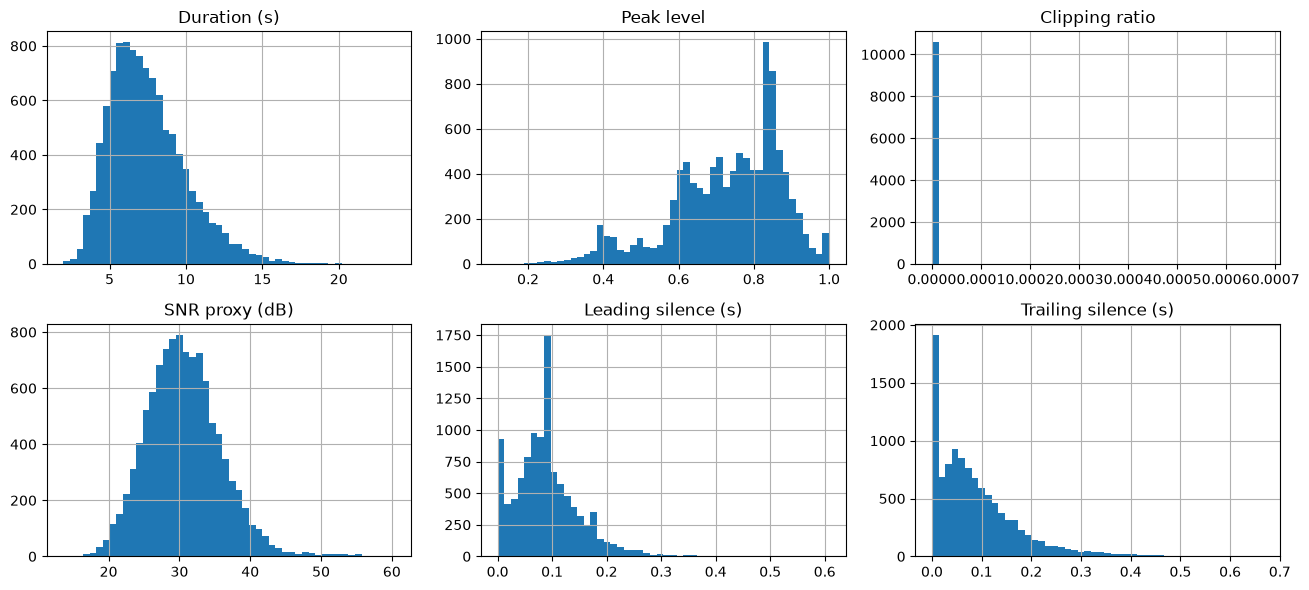

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, (c, t) in zip(ax.ravel(), [("dur","Duration (s)"),("peak","Peak level"),("clip_ratio","Clipping ratio"),
                                  ("snr_proxy","SNR proxy (dB)"),("lead_sil","Leading silence (s)"),("trail_sil","Trailing silence (s)")]):
    man[c].dropna().hist(bins=50, ax=a); a.set_title(t)
plt.tight_layout(); plt.savefig(PROC_DIR/"reports"/"quality_histograms.png", dpi=130); plt.show()

## 4. Transcript–audio mismatch check
If the text and audio do not match (wrong sentence, missing words, extra speech), TTS training breaks silently.

**Idea:** people speak at a fairly steady rate, so **characters per second of speech** should be roughly constant. Outliers (very fast or very slow) are suspicious. We use a *robust* z-score (median and MAD), so a few bad files cannot distort the baseline.

median 13.7 chars/s, robust SD 1.3


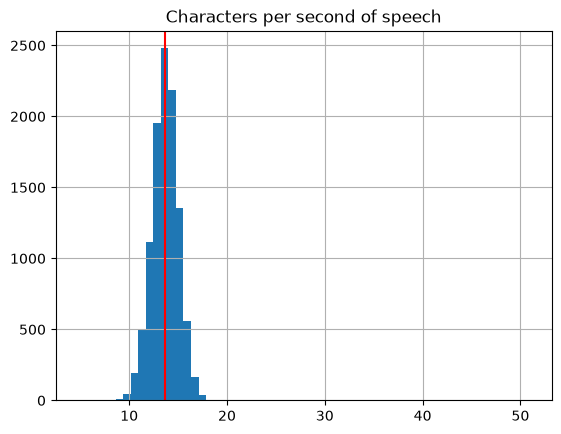

Suspicious pairs (|z| > 4.0 ): 15


,Sentence ID,text,speech_dur,cps,cps_z
314,recipes_14_0001_0017,នំក្រម៉ៅថត ឬ នំអំបុកបំពង អាចទទួលទានទាំងក្តៅៗ ឬ...,13.557333,4.794453,-6.967825
379,recipes_17_0001_0005,ចំណែកឯផ្លែឈើដែលគេពេញនិយម យកមកក្រឡុកជាមួយមានដូច...,13.258667,8.221038,-4.289852
403,recipes_18_0001_0004,ចំណែកឯបន្លែវិញមានដូចជា ត្រសក់ ប៉េងប៉ោះ ជីរនាងវ...,9.777500,8.386602,-4.160459
3430,recipes_120_0006_0015,ការលាយគ្រឿងផ្សំទាំងអស់នេះ ត្រូវធ្វើឡើងដោយប្រុង...,4.266667,19.218750,4.305172
3572,recipes_124_0007_0007,ការចំហុយមិនខុសពីអាំងទេ គ្រាន់តែគេយកទៅចំហុយក្នុ...,4.394667,20.251820,5.112545
6996,burials_21_0001_0005,ដោយសារតែការនេះ គ្រួសាររបស់អ្នកស្លាប់ពឹងផ្អែកយ៉...,4.465750,20.825169,5.560634
7408,hospitality_08_0001_0012,ឯការញញឹម ក៏ជាកាយវិការមួយដែលបង្ហាញពីភាពរាក់ទាក់...,4.476417,21.445725,6.045615
6958,burials_19_0001_0026,មួយវិញទៀត នៅគ្រប់ស្រុកក្នុងប្រទេសកម្ពុជា គេតែង...,4.497750,21.566339,6.139879
6306,wedding_29_0001_0018,ការរៀបអាពាហ៍ពិពាហ៍ជាផ្លូវការ គឺធ្វើឡើងដើម្បីឲ្...,4.455083,22.221807,6.652145
5855,wedding_16_0001_0008,នៅក្នុងកិច្ចប្រជុំពិភាក្សា រាល់ពាក្យសម្ដី និងក...,4.380417,24.655189,8.553902


In [10]:
man["cps"] = man["n_chars"] / man["speech_dur"]
med = man["cps"].median(); mad = max((man["cps"] - med).abs().median() * 1.4826, 1.0)   # floor avoids dividing by ~0
man["cps_z"] = (man["cps"] - med) / mad
print(f"median {med:.1f} chars/s, robust SD {mad:.1f}")
man["cps"].hist(bins=60); plt.axvline(med, c="r"); plt.title("Characters per second of speech"); plt.show()
print("Suspicious pairs (|z| >", MISMATCH_Z, "):", (man.cps_z.abs() > MISMATCH_Z).sum())
man.loc[man.cps_z.abs() > MISMATCH_Z, ["Sentence ID","text","speech_dur","cps","cps_z"]].sort_values("cps_z").head(10)

## 5. Decide what to reject
Each rule adds a reason. A file is kept only if it has **no** reasons. All rejected files are saved with their reasons, so you can defend the choices in the report.

In [11]:
snr_cut = man["snr_proxy"].quantile(SNR_PCT/100)
reasons = pd.DataFrame({
    "corrupt":   ~man.hdr_ok | ~man.read_ok,
    "too_short": man.dur < MIN_DUR,
    "too_long":  man.dur > MAX_DUR,
    "clipped":   man.clip_ratio > MAX_CLIP_RATIO,
    "too_quiet": man.peak < MIN_PEAK,
    "noisy":     man.snr_proxy < snr_cut,
    "mismatch":  man.cps_z.abs() > MISMATCH_Z,
}).fillna(False)

man["reject_reason"] = reasons.apply(lambda r: ",".join(r.index[r]), axis=1)
man["keep"] = man["reject_reason"] == ""
print(reasons.sum().to_string())
print(f"\nKEEP {man.keep.sum()} / {len(man)}  ({man.keep.mean()*100:.1f}%)")

man.drop(columns=["src_path"]).to_csv(PROC_DIR/"reports"/"quality_report.csv", index=False)
man.loc[~man.keep, ["Sentence ID","text","reject_reason"]].to_csv(PROC_DIR/"reports"/"rejected.csv", index=False)

corrupt        0
too_short      0
too_long      89
clipped        0
too_quiet      0
noisy        107
mismatch      15

KEEP 10410 / 10621  (98.0%)


## 6. Standardize the audio
For each kept file:
1. **Mono**: average channels.
2. **Resample** to `TARGET_SR`.
3. **Trim silence** at both ends, but keep `KEEP_PAD` seconds so words do not sound cut off.
4. **Loudness normalize** to `TARGET_LUFS`, so the model does not learn volume differences. Then limit the peak so nothing clips.
5. Save as **16-bit PCM WAV** named `{Sentence ID}.wav`.

The cell skips files that already exist, so you can stop and re-run it safely.

In [12]:
import pyloudnorm as pyln
meter = pyln.Meter(TARGET_SR)

def process(row):
    sid, src = row
    out = PROC_DIR/"wavs"/f"{sid}.wav"
    try:
        if not out.exists():
            x, sr = sf.read(src, always_2d=True, dtype="float32")
            x = x.mean(axis=1)
            if sr != TARGET_SR:
                x = librosa.resample(x, orig_sr=sr, target_sr=TARGET_SR)
            _, (s, e) = librosa.effects.trim(x, top_db=TRIM_DB)
            pad = int(KEEP_PAD * TARGET_SR)
            x = x[max(0, s-pad): min(len(x), e+pad)]
            try:
                loud = meter.integrated_loudness(x)
                x = pyln.normalize.loudness(x, loud, TARGET_LUFS)
            except Exception:
                x = x / (np.abs(x).max() + 1e-9) * 0.9      # fallback: peak normalize
            pk = np.abs(x).max()
            if pk > 0.95: x = x * (0.95 / pk)                 # safety limiter
            sf.write(out, x, TARGET_SR, subtype="PCM_16")
        return sf.info(out).duration
    except Exception:
        return None

todo = man[man.keep]
with ThreadPoolExecutor(N_WORKERS) as ex:
    durs = list(tqdm(ex.map(process, zip(todo["Sentence ID"], todo["src_path"])), total=len(todo)))
man.loc[todo.index, "new_dur"] = durs
print("failed during processing:", sum(d is None for d in durs))

  3%|▎         | 356/10410 [00:01<00:53, 186.94it/s]c:\Users\MSI\anaconda3\envs\khmer_tts\Lib\site-packages\pyloudnorm\normalize.py:62: UserWarning: Possible clipped samples in output.
  warnings.warn("Possible clipped samples in output.")
  6%|▌         | 576/10410 [00:02<00:45, 214.24it/s]c:\Users\MSI\anaconda3\envs\khmer_tts\Lib\site-packages\pyloudnorm\normalize.py:62: UserWarning: Possible clipped samples in output.
  warnings.warn("Possible clipped samples in output.")
100%|██████████| 10410/10410 [00:47<00:00, 220.86it/s]

failed during processing: 0


In [13]:
# final filter on the processed length, then keep only what we need
final = man[man.keep & man.new_dur.between(0.8, MAX_DUR)].copy()
print(f"Final dataset: {len(final)} clips | {final.new_dur.sum()/3600:.2f} h | mean {final.new_dur.mean():.2f}s")

Final dataset: 10410 clips | 21.38 h | mean 7.39s


### Listen and look: original vs processed
Always check by ear. Do the processed clips sound the same, only cleaner and equally loud?

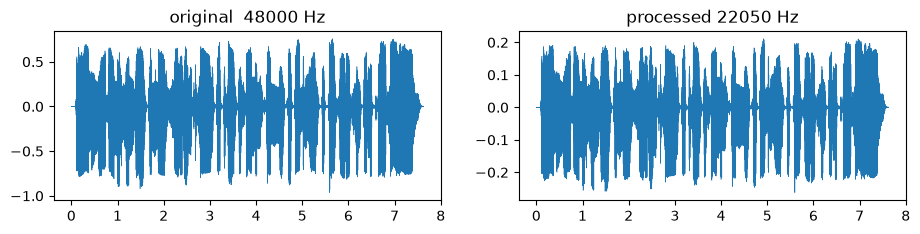

ត្រូវអនុញ្ញាតឱ្យអ្នកមានវ័យចំណាស់ ឬរៀមច្បងចាប់ផ្ដើមពិសារមុនសិន នេះជាការបង្ហាញពីការគោរព និងគុណធម៌ដ៏ល្អ។


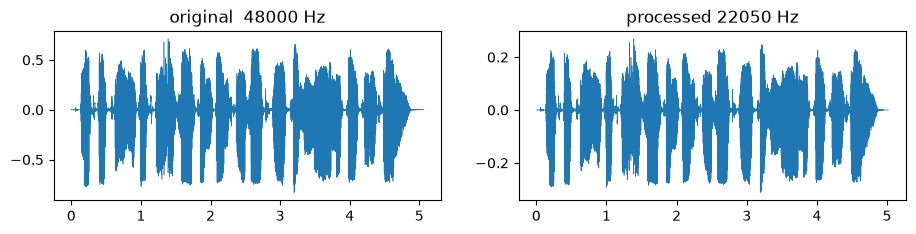

នៅផ្ទះខ្លះ ម្ចាស់ផ្ទះអាចដើរចេញតាមភ្ញៀវដល់ទ្វារ ជាសញ្ញានៃការជូនផ្លូវ។


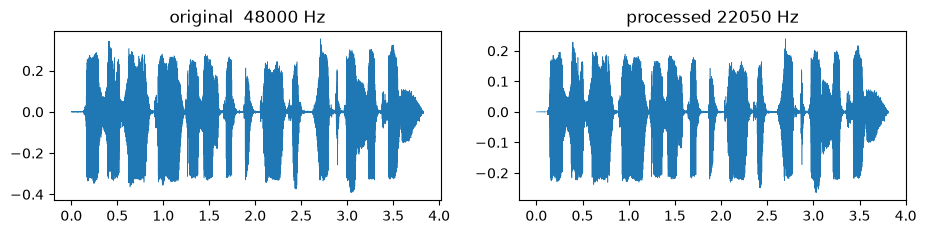

ការបោះបាយចោលត្រូវបានចាត់ទុកថាជាបាបកម្មដ៏ធំ។


In [14]:
samp = final.sample(3, random_state=1)
for _, r in samp.iterrows():
    o, osr = sf.read(r["src_path"], dtype="float32"); o = o.mean(axis=1) if o.ndim > 1 else o
    n, nsr = sf.read(PROC_DIR/"wavs"/f"{r['Sentence ID']}.wav", dtype="float32")
    fig, ax = plt.subplots(1, 2, figsize=(11, 2.2))
    ax[0].plot(np.arange(len(o))/osr, o, lw=.4); ax[0].set_title(f"original  {osr} Hz")
    ax[1].plot(np.arange(len(n))/nsr, n, lw=.4); ax[1].set_title(f"processed {nsr} Hz"); plt.show()
    print(r["text"]); display(Audio(o, rate=osr)); display(Audio(n, rate=nsr))

## 7. Train / validation / test split
- **train**: the model learns from it.
- **val**: small set to watch overfitting during training.
- **test**: never touched in training; used for CER and MOS in Step 4.

 **Split by paragraph, not by random sentence.** Neighbouring sentences in a paragraph share vocabulary and topic. If one is in train and the next in test, the test looks easier than reality (*data leakage*). We keep each paragraph in a single split, and sample per topic, so every topic appears in val and test.

In [15]:
final["group"] = final["Sentence ID"].str.rsplit("_", n=1).str[0]    # topic_subtopic_paragraph
rng = np.random.default_rng(SEED)
split = {}
for topic, g in final.groupby("Topic"):
    groups = g["group"].unique(); rng.shuffle(groups)
    n_test, n_val = max(1, round(len(g)*TEST_FRAC)), max(1, round(len(g)*VAL_FRAC))
    c_test = c_val = 0
    for grp in groups:
        size = (g["group"] == grp).sum()
        # take a paragraph only if it doesn't overshoot the target by much
        if c_test < n_test and (c_test == 0 or c_test + size <= 1.3 * n_test):
            split[grp] = "test"; c_test += size
        elif c_val < n_val and (c_val == 0 or c_val + size <= 1.3 * n_val):
            split[grp] = "val";  c_val += size
        else:
            split[grp] = "train"
final["split"] = final["group"].map(split)

summary = final.groupby("split").agg(clips=("Sentence ID","count"), hours=("new_dur", lambda s: s.sum()/3600)).round(2)
display(summary)
display(pd.crosstab(final["Topic"], final["split"]))
assert not (set(final[final.split=="train"].group) & set(final[final.split!="train"].group)), "leakage!"

,clips,hours
split,,
test,399,0.90
train,9616,19.66
val,395,0.82


split,test,train,val
Topic,,,
Burials,49,678,25
Dining,25,532,34
Etiquettes,35,427,28
Giving Gift,36,1000,45
Greetings,18,648,28
Hospitality,46,533,24
Local Name,35,340,28
Public Holiday,32,185,38
Recipes,77,3449,88


## 8. Export for the VITS trainer
Format used by the Coqui `ljspeech` reader: `file_id|raw text|normalized text` (one line per clip; the audio is `wavs/file_id.wav`). Our text is already cleaned, so both columns are identical.

In [16]:
assert not final["text"].str.contains(r"\|").any(), "a '|' inside the text would break the format"
for name in ["train", "val", "test"]:
    d = final[final.split == name]
    with open(PROC_DIR/f"metadata_{name}.csv", "w", encoding="utf-8", newline="\n") as f:
        for sid, t in zip(d["Sentence ID"], d["text"]):
            f.write(f"{sid}|{t}|{t}\n")
    print(name, len(d))

final.drop(columns=["src_path"]).to_csv(PROC_DIR/"dataset_final.csv", index=False)

# character inventory the model will learn (Step 3 needs this)
chars = sorted(set("".join(final["text"])))
print(len(chars), "unique characters")
(PROC_DIR/"characters.txt").write_text("".join(chars), encoding="utf-8")
print("".join(chars))

train 9616
val 395
test 399
81 unique characters
 !',.?កខគឃងចឆជឈញដឋឌឍណតថទធនបផពភមយរលវសហឡអឥឦឧឪឫឬឭឮឯឱឲឳាិីឹឺុូួើឿៀេែៃោៅំះៈ៉៊់៌៍៏័៑្។ៗ
